# Scraping: moving the dual current onto the power ellipsoid

After GCD, the Lagrangian of the scattered-power bound sits on the PSD boundary and the dual current $x^\star$ is not unique; it lies
off the global real-power ellipsoid (relative distance $d \sim 10^{-3}$) and violates the reactive power by orders more.
Scraping (AToM notes, Section *Scraping*) perturbs the excitation so that the stationary point of the previous Lagrangian becomes
the projection $x_\mathrm{p}$ of $x^\star$ onto the ellipsoid, re-solves the dual, and repeats:
$$\delta s_j = A_{\phi j}(x_{\mathrm{p},j} - x_{\phi j}), \qquad V_{j+1} = V_j + \eta_j\, S(\lambda_j)^{-1}\delta s_j ,$$
with $s(\lambda; V) = S(\lambda) V = -\tfrac12 W^H (q \odot V)$, $q = \sum_k \lambda_k \overline{p'_k}$, so $S(\lambda)^{-1}\delta s = -2\,(Z_0^H \delta s)/q$.
The step is accepted when the dual value follows its first-order prediction $D_j + 2\eta_j\operatorname{Re}[x_{\phi j}^H \delta s_j]$ within $\tau |D_j|$.

The question studied here: **does the dual current move towards the ellipsoid boundary?** Two targets are compared,
the ellipsoid of the original excitation $V$ (physical) and that of the perturbed excitation $V_j$ (strong duality of the perturbed problem).

Setup as in `VscatBound.ipynb` (copper 2:1 patch, $ka = 1$, `patch21ka1`, scattered-voltage basis $x = V_\mathrm{sca}$).

In [2]:
import numpy as np
import scipy.sparse as sp
import time
from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
import copy
import matplotlib.pyplot as plt
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [3]:
matrixSet = "patch21ka1"   # "dipole" | "patch21ka1": operators loaded from *_{matrixSet}.txt (both ka = 1)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
wavelength = c / frequency # wavelength in m
print(f"Wavelength: {wavelength} m")

ka = 1 # electrical size of the antenna
k = 2 * np.pi / wavelength # wavenumber
a = ka / k # antenna circumradius
print(f"Antenna circumradius: {a} m")

omega = 2 * np.pi * frequency # angular frequency

conductivity_reduction_factor = 1 # factor to reduce conductivity for testing purposes
copper_conductivity = conductivity_reduction_factor*5.96e7 # S/m
copper_permittivity = 1 + 1j * copper_conductivity / (omega * epsilon_0) # copper permittivity in dimensionless units
print(f"Copper permittivity: {copper_permittivity:.2e}")

Wavelength: 0.1223655664053944 m
Antenna circumradius: 0.019475084757658086 m
Copper permittivity: 1.00e+00+4.37e+08j


In [4]:
# Calculate surface impedance
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta)
print(f"Surface impedance: {Zs} Ω")

# Load matrices from text files
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Lchol = np.linalg.cholesky(Lmat).conj().T
LcholInv = np.linalg.inv(Lchol)

def Msym(M):
    return(0.5*(M.conj().T + M))

def Mchol(M):
    return(Msym(LcholInv.conj().T @ M @ LcholInv))

R0 = np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',') # radiated power matrix
R0 = Mchol(R0)

X0 = np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',') # reactive power matrix
X0 = Mchol(X0)

Vinc = np.loadtxt(f"V_{matrixSet}.txt", delimiter=',') # voltage excitation vector
Vinc = E0*Vinc
def Vchol(v):
    return(LcholInv.conj().T @ v)
Vinc = Vchol(Vinc)

Zmat = Zs * np.eye(Ndes) # material impedance matrix
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix

def evalObjI(Ivec):
    # radiated power in the current basis
    return(0.5*np.real(Ivec.conj().T @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc) # current distribution for full plate
Pfull = evalObjI(Ifull) # objective for full plate
print(f"Objective for full plate: {Pfull:.6e} W")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω
Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W


In [5]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0)   # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0

def VtoI(Vsca):
    return(-W @ Vsca)

def evalObj(Vsca):
    return(-np.real(Vsca.conj().T @ Obj @ Vsca) + 2*np.real(Vsca.conj().T @ obj) + obj0)

Vfull = -Z0 @ Ifull # scattered voltage for full plate
print(f"Objective for full plate in Vsca: {evalObj(Vfull):.6e} W (I basis {Pfull:.6e} W)")

cond(Z0) = 1.174e+03
Objective for full plate in Vsca: 4.114174e-02 W (I basis 4.114174e-02 W)


In [6]:
A1 = np.eye(Ndes) + np.conj(Zs) * WH
A2 = W
s1 = -0.5 * Vinc

qList = [1, -1j]   # real and imaginary part (real and reactive power), p = q 1
Plist = [sp.diags(np.conj(q)*np.ones(Ndes, dtype=complex)) for q in qList]   # P' = diag(p^*)

def projRes(x, Pp):
    # Re(-x^H A1 P' A2 x + 2 x^H A2^H P'^H s1)
    return(np.real(-x.conj() @ A1 @ (Pp @ (A2 @ x)) + 2*x.conj() @ (A2.conj().T @ (Pp.conj().T @ s1))))

def directRes(Vsca, p):
    # Re[I^H diag(p) (V + Vsca - Zs I)] evaluated directly
    I = VtoI(Vsca)
    return(np.real(np.sum(p*np.conj(I)*(Vinc + Vsca - Zs*I))))

print("power conservation residuals at full plate:",
      [f"{projRes(Vfull, Pp):.2e} (direct {directRes(Vfull, q*np.ones(Ndes)):.2e})" for Pp, q in zip(Plist, qList)])

# check: shared projector form equals the direct constraint for a random projector at a random point
pRand = np.random.randn(Ndes) + 1j*np.random.randn(Ndes)
xRand = np.random.randn(Ndes) + 1j*np.random.randn(Ndes)
print(f"random p, random x: shared form {projRes(xRand, sp.diags(np.conj(pRand))):.6e}, direct {directRes(xRand, pRand):.6e}")

power conservation residuals at full plate: ['-1.39e-17 (direct -2.89e-17)', '4.44e-16 (direct -4.76e-16)']
random p, random x: shared form -4.370125e+00, direct -4.370125e+00


In [7]:
QCQP = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, Plist, A2=A2, verbose=1)

lags_init = np.array([1.0, 0.0])   # lambda = 1 on the real power constraint
print(f"initial lags dual feasible: {QCQP.is_dual_feasible(lags_init)}")

opt_params = OptimizationHyperparameters(opttol=1e-6,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=10,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

t1 = time.time()
result = QCQP.solve_current_dual_problem(method='newton', init_lags=lags_init, opt_params=opt_params)
print(f"bound: {result[0]:.6e} W, time: {time.time()-t1:.2f}s, Lagrange multipliers: {QCQP.current_lags}")

Precomputed 2 A matrices and Fs vectors.
initial lags dual feasible: True
bound: 1.847944e+01 W, time: 0.11s, Lagrange multipliers: [ 8.83797881e-01 -4.10993941e-05]


## GCD

100 GCD iterations as in `VscatBound.ipynb` (about 12 minutes). Set `cacheFile` to a path to store and reuse the GCD state
(projectors and multipliers); GCD contains randomness, so a fresh run differs by about $10^{-3}$ in $d$.

In [9]:
Ngcd = 20
cacheFile = None   # e.g. "scraping_gcd100.npz"

import os
if cacheFile is not None and os.path.exists(cacheFile):
    st = np.load(cacheFile)
    PlistG = [sp.diags(st['Pdata'][:, k]) for k in range(st['Pdata'].shape[1])]
    gQCQP = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistG, A2=A2, verbose=0)
    gQCQP.current_lags = st['lags']
    gQCQP.current_dual = gQCQP.get_dual(gQCQP.current_lags)[0]
    gQCQP.current_xstar = gQCQP._get_xstar(gQCQP.current_lags)[0]
else:
    gQCQP = copy.deepcopy(QCQP)
    gQCQP.verbose = 0
    t1 = time.time()
    gQCQP.run_gcd(GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd, max_gcd_iter_num=Ngcd,
                                     gcd_iter_period=Ngcd + 1, opt_params=opt_params))
    print(f"GCD time {time.time()-t1:.1f}s")
    if cacheFile is not None:
        np.savez(cacheFile, Pdata=gQCQP.Proj.get_Pdata_column_stack(), lags=gQCQP.current_lags)
gcdLags = gQCQP.current_lags.copy()
print(f"GCD bound {gQCQP.current_dual:.6e} W, {gQCQP.n_proj_constr} projectors")

At GCD iteration #1, best dual bound found is             18.479439958269765.
min eigenvalue: 6.851365e-09
At GCD iteration #2, best dual bound found is             18.33156335943524.
min eigenvalue: 5.900530e-09
At GCD iteration #3, best dual bound found is             18.219582847407164.
min eigenvalue: 3.891570e-09
At GCD iteration #4, best dual bound found is             18.11634527916543.
min eigenvalue: 1.260088e-09
At GCD iteration #5, best dual bound found is             18.058141943984293.
min eigenvalue: 3.000882e-10
At GCD iteration #6, best dual bound found is             18.014874478570018.
min eigenvalue: 4.902959e-11
At GCD iteration #7, best dual bound found is             17.99693023496288.
min eigenvalue: 3.607547e-10
At GCD iteration #8, best dual bound found is             17.97685958329899.
min eigenvalue: 3.859627e-13
At GCD iteration #9, best dual bound found is             17.966632015856657.
min eigenvalue: 2.463271e-13
At GCD iteration #10, best dual bound fou

## Power ellipsoid and distance

With $R = \operatorname{Re} Z_\mathrm{tot} = C^H C$ (whitened basis), the real power $I^H R I - \operatorname{Re}(I^H V) = 0$ is the ellipsoid
$(I - I_\mathrm{c})^H R (I - I_\mathrm{c}) = r^2$, $I_\mathrm{c} = \tfrac12 R^{-1}V$, $r^2 = \tfrac14 V^H R^{-1} V$. For $I = -W x$,
$$d = \frac{\|C(I - I_\mathrm{c})\| - r}{r}, \qquad I_\mathrm{p} = I_\mathrm{c} + \frac{r}{\|C(I-I_\mathrm{c})\|}(I - I_\mathrm{c}), \qquad x_\mathrm{p} = -Z_0 I_\mathrm{p},$$
and the reactive residual is reported as $c_\mathrm{im}/r^2$, $c_\mathrm{im} = \operatorname{Re}[I^H X I + I^H jV]$ (a hyperboloid, no center).

In [10]:
Rtot = Msym(Ztot)
Xtot = (Ztot - Ztot.conj().T) / 2j
Crt = np.linalg.cholesky(Rtot).conj().T

def ellipsoid(V):
    Ic = 0.5 * np.linalg.solve(Rtot, V)
    r = 0.5 * np.sqrt(np.real(V.conj() @ np.linalg.solve(Rtot, V)))
    return Ic, r

def measures(x, V):
    # relative distance from the real-power ellipsoid of V, normalized reactive residual
    I = VtoI(x)
    Ic, r = ellipsoid(V)
    d = (np.linalg.norm(Crt @ (I - Ic)) - r) / r
    cim = np.real(I.conj() @ Xtot @ I + I.conj() @ (1j * V)) / r**2
    return d, cim

def project(x, V):
    # radial projection of x onto the real-power ellipsoid of V
    I = VtoI(x)
    Ic, r = ellipsoid(V)
    Ip = Ic + r / np.linalg.norm(Crt @ (I - Ic)) * (I - Ic)
    return -Z0 @ Ip

Ic, r = ellipsoid(Vinc)
print(f"r^2 = {r**2:.6e} W")
for name, x in [("full plate", Vfull), ("global constraints", QCQP.current_xstar), (f"GCD {Ngcd}", gQCQP.current_xstar)]:
    d, cim = measures(x, Vinc)
    print(f"{name:20s} d = {d:+.3e}, c_im/r^2 = {cim:+.3e}")

r^2 = 1.149400e+01 W
full plate           d = -2.620e-16, c_im/r^2 = -1.932e-16
global constraints   d = +5.884e-09, c_im/r^2 = -6.329e-05
GCD 20               d = -1.832e-03, c_im/r^2 = +5.290e+02


## Scraping loop

The perturbed source changes only the linear term $s_1 = -V/2$, so the multipliers $\lambda_j$ stay dual feasible and warm-start the next solve.
Each step records $D_j$, $d_j$ and $c_{\mathrm{im},j}/r^2$ with respect to the original $V$ and the perturbed $V_j$, the relative perturbation
$e_j = \|V_j - V\|/\|V\|$, and the smallest eigenvalue of $A(\lambda_j)$.

In [11]:
def scrape(target, J=8, tau=1e-2):
    # target: "original" (ellipsoid of Vinc) or "own" (ellipsoid of the current V_j)
    Q = copy.deepcopy(gQCQP)
    Q.s1 = -0.5 * Vinc
    Q.compute_precomputed_values()
    lags = gcdLags.copy()
    Q.solve_current_dual_problem('newton', init_lags=lags, opt_params=opt_params)
    lags, x, V, D = Q.current_lags.copy(), Q.current_xstar.copy(), Vinc.copy(), Q.current_dual
    q = lambda lg: Q.Proj.Pdiags.conj() @ lg[:Q.n_proj_constr]
    assert np.allclose(Q._get_total_S(lags), A2.conj().T @ (q(lags) * (-0.5 * V)))   # S(lambda) V
    hist = []
    def record(j, eta, lin):
        dO, cO = measures(x, Vinc); dJ, cJ = measures(x, V)
        A = Msym(Q._get_total_A(lags))
        hist.append(dict(j=j, eta=eta, D=D, lin=lin, d=dO, cim=cO, dOwn=dJ, cimOwn=cJ,
                         e=np.linalg.norm(V - Vinc)/np.linalg.norm(Vinc), mineig=np.linalg.eigvalsh(A)[0],
                         A=A, s=Q._get_total_S(lags), x=x.copy()))
    record(0, 0.0, D)
    for j in range(1, J + 1):
        A = Q._get_total_A(lags)
        xp = project(x, Vinc if target == "original" else V)
        ds = A @ (xp - x)
        dV = -2 * (Z0.conj().T @ ds) / q(lags)
        eta = 1.0
        while True:
            Vn = V + eta * dV
            Q.s1 = -0.5 * Vn
            Q.compute_precomputed_values()
            lin = D + 2 * eta * np.real(x.conj() @ ds)
            Q.solve_current_dual_problem('newton', init_lags=lags, opt_params=opt_params)
            if abs(Q.current_dual - lin) <= tau * abs(D) or eta < 1e-3:
                break
            eta /= 2
        lags, x, V, D = Q.current_lags.copy(), Q.current_xstar.copy(), Vn, Q.current_dual
        record(j, eta, lin)
    return hist

def show(hist, title):
    print(title)
    print(f"{'j':>2} {'eta':>5} {'D_j (W)':>12} {'lin (W)':>12} {'d(V)':>10} {'cim(V)/r2':>10} {'d(Vj)':>10} {'cim(Vj)/r2':>10} {'e_j':>9} {'min eig':>9}")
    for h in hist:
        print(f"{h['j']:2d} {h['eta']:5.2f} {h['D']:12.6e} {h['lin']:12.6e} {h['d']:+10.3e} {h['cim']:+10.3e} "
              f"{h['dOwn']:+10.3e} {h['cimOwn']:+10.3e} {h['e']:9.2e} {h['mineig']:9.2e}")

t1 = time.time()
histO = scrape("original")
show(histO, "target: ellipsoid of the original excitation V")
histJ = scrape("own")
show(histJ, "\ntarget: ellipsoid of the perturbed excitation V_j")
print(f"\n{time.time()-t1:.1f}s")

target: ellipsoid of the original excitation V
 j   eta      D_j (W)      lin (W)       d(V)  cim(V)/r2      d(Vj) cim(Vj)/r2       e_j   min eig
 0  0.00 1.777809e+01 1.777809e+01 -1.851e-03 +5.292e+02 -1.851e-03 +5.292e+02  0.00e+00  5.66e-15
 1  1.00 1.780638e+01 1.780636e+01 -4.213e-04 +5.286e+02 -1.818e-03 +5.290e+02  1.03e-03  4.24e-14
 2  1.00 1.781284e+01 1.781283e+01 -8.844e-05 +5.313e+02 -1.804e-03 +5.317e+02  1.27e-03  4.76e-14
 3  1.00 1.781419e+01 1.781419e+01 +1.107e-05 +5.301e+02 -1.771e-03 +5.305e+02  1.32e-03  4.34e-14
 4  1.00 1.781402e+01 1.781402e+01 -2.389e-05 +5.308e+02 -1.798e-03 +5.312e+02  1.31e-03  4.21e-14
 5  1.00 1.781439e+01 1.781439e+01 +8.841e-06 +5.305e+02 -1.783e-03 +5.309e+02  1.32e-03  4.28e-14
 6  1.00 1.781425e+01 1.781425e+01 +2.017e-05 +5.298e+02 -1.765e-03 +5.302e+02  1.32e-03  4.38e-14
 7  1.00 1.781394e+01 1.781394e+01 -3.525e-05 +5.314e+02 -1.805e-03 +5.318e+02  1.31e-03  3.94e-14
 8  1.00 1.781448e+01 1.781448e+01 +2.851e-05 +5.299e+02 -1.76

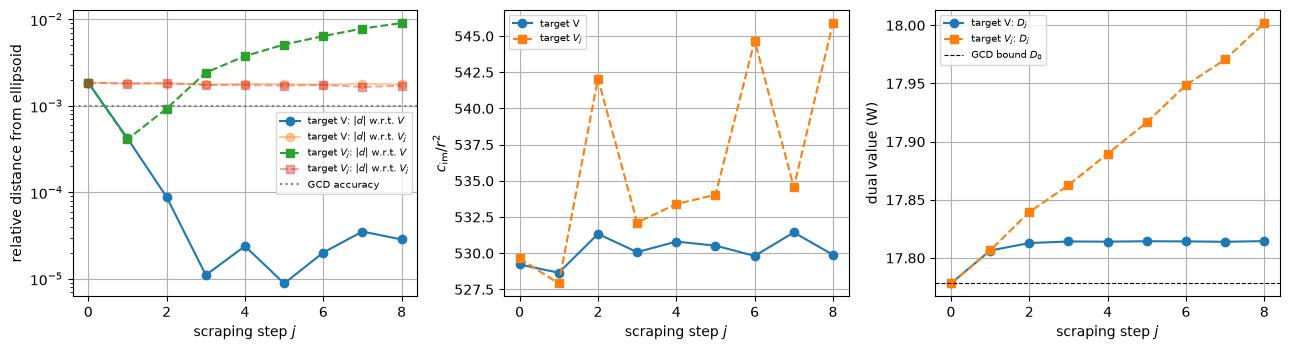

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for hist, lab, m in [(histO, "target V", 'o-'), (histJ, r"target $V_j$", 's--')]:
    j = [h['j'] for h in hist]
    axes[0].semilogy(j, [abs(h['d']) for h in hist], m, label=f"{lab}: $|d|$ w.r.t. $V$")
    axes[0].semilogy(j, [abs(h['dOwn']) for h in hist], m, alpha=0.4, label=f"{lab}: $|d|$ w.r.t. $V_j$")
    axes[1].plot(j, [h['cim'] for h in hist], m, label=lab)
    axes[2].plot(j, [h['D'] for h in hist], m, label=f"{lab}: $D_j$")
axes[0].axhline(1e-3, c='gray', ls=':', label='GCD accuracy')
axes[0].set_xlabel('scraping step $j$'); axes[0].set_ylabel('relative distance from ellipsoid'); axes[0].legend(fontsize=7)
axes[1].set_xlabel('scraping step $j$'); axes[1].set_ylabel(r'$c_\mathrm{im}/r^2$'); axes[1].legend(fontsize=7)
axes[2].axhline(gQCQP.current_dual, c='k', ls='--', lw=0.8, label='GCD bound $D_0$')
axes[2].set_xlabel('scraping step $j$'); axes[2].set_ylabel('dual value (W)'); axes[2].legend(fontsize=7)
for ax in axes: ax.grid(True)
plt.tight_layout(); plt.show()

## Chained center

The dual solutions of the run towards the original ellipsoid are chained with Frobenius-normalized Lagrangians
$\hat A_j = A_{\phi j}/\|A_{\phi j}\|_\mathrm{F}$, $\hat s_j = s_{\phi j}/\|A_{\phi j}\|_\mathrm{F}$ and the U-shaped weights
$$\omega_j = \exp(-e_j/\tau_V) + \frac{\tau_d}{|d_j| + \tau_d},$$
giving $A_\mu = \sum_j \mu_j \hat A_j$, $s_\mu = \sum_j \mu_j \hat s_j$ and the chained center $\bar x_\mu = A_\mu^{-1} s_\mu$, the target of the chained density fit.

In [13]:
tauD, tauV = 1e-3, 1e-3
om = np.array([np.exp(-h['e']/tauV) + tauD/(abs(h['d']) + tauD) for h in histO])
mu = om / om.sum()
Amu = sum(m * h['A']/np.linalg.norm(h['A']) for m, h in zip(mu, histO))
smu = sum(m * h['s']/np.linalg.norm(h['A']) for m, h in zip(mu, histO))
ev = np.linalg.eigvalsh(Amu)
xbar = np.linalg.solve(Amu, smu)
print("weights mu_j:", np.array2string(mu, precision=3))
print(f"A_mu eigenvalues: min {ev[0]:.3e}, max {ev[-1]:.3e} (single A_j: min {min(np.linalg.eigvalsh(h['A']/np.linalg.norm(h['A']))[0] for h in histO):.3e})")
d, cim = measures(xbar, Vinc)
print(f"chained center: d = {d:+.3e}, c_im/r^2 = {cim:+.3e}, P = {evalObj(xbar):.6e} W, "
      f"relative difference from x_0: {np.linalg.norm(xbar - histO[0]['x'])/np.linalg.norm(histO[0]['x']):.3e}")

weights mu_j: [0.122 0.096 0.108 0.113 0.112 0.113 0.112 0.111 0.112]
A_mu eigenvalues: min 1.702e-11, max 6.361e-01 (single A_j: min 2.452e-12)
chained center: d = -2.929e-04, c_im/r^2 = +5.312e+02, P = 1.780861e+01 W, relative difference from x_0: 8.312e-02


## Chained density fit

The density $\rho \in [0,1]^N$ is fitted by the joint problem (Frobenius-normalized norm matrices, $M_0 = \mathbf{1}/\sqrt{N}$)
$$\min_{\rho,\,\tilde x}\ \|x(\rho) - \tilde x\|^2_{M_0} + \sum_j \mu_j \|\tilde x - x_{\phi j}\|^2_{\hat A_j},\qquad \mu_j = \mu\,\frac{\omega_j}{\sum_l \omega_l},$$
where $x(\rho) = -Z_0 I(\rho)$ is the scattered voltage of the structure with density $\rho$, $(Z_s + \rho Z_0) I = \rho V$ (original excitation).
The inner minimization is closed form, $(M_0 + A_\mu)\tilde x = M_0 x(\rho) + s_\mu$, which avoids the singular $A_\mu^{-1}$ of the reduced form; by the envelope theorem
$\partial f/\partial x^* = M_0(x - \tilde x)$, and one adjoint solve gives
$$\frac{\partial f}{\partial \rho_i} = -2\operatorname{Re}\left[\overline{w_i}\,(V - Z_0 I)_i\right],\qquad w = (Z_s + \rho Z_0)^{-H} Z_0^H M_0 (x - \tilde x).$$
The bounded problem is solved by L-BFGS-B from 10 starts (separable current fit of $x_0$, uniform $0.5$, 8 random), for the chained weights and,
for comparison, for a single Lagrangian ($j = 0$, unperturbed GCD; $j = J$, last scraping step). Each density is evaluated by its realized
scattered power $P(\rho)$ and by the best binary structure over thresholds $0.05, \dots, 0.95$.

In [14]:
from scipy.optimize import minimize

m0 = 1 / np.sqrt(Ndes)

def chain(hist, mu_tot, only=None, tauD=1e-3, tauV=1e-3):
    # normalized chained Lagrangian A_mu, s_mu and the constant making each term a squared norm
    if only is None:
        om = np.array([np.exp(-h['e']/tauV) + tauD/(abs(h['d']) + tauD) for h in hist])
    else:
        om = np.array([1.0 if j in only else 0.0 for j in range(len(hist))])
    mu = mu_tot * om / om.sum()
    nA = [np.linalg.norm(h['A']) for h in hist]
    Amu = sum(m * h['A']/n for m, h, n in zip(mu, hist, nA))
    smu = sum(m * h['s']/n for m, h, n in zip(mu, hist, nA))
    cst = sum(m * np.real(h['x'].conj() @ h['s'])/n for m, h, n in zip(mu, hist, nA))
    return Amu, smu, cst

def chainedObjective(Amu, smu, cst):
    K = np.linalg.inv(m0 * np.eye(Ndes) + Amu)
    def f(rho):
        S = np.diag(rho.astype(complex))
        M = Zs * np.eye(Ndes) + S @ Z0
        I = np.linalg.solve(M, S @ Vinc)
        x = -Z0 @ I
        xt = K @ (m0 * x + smu)
        val = m0 * np.linalg.norm(x - xt)**2 + np.real(xt.conj() @ Amu @ xt) - 2*np.real(xt.conj() @ smu) + cst
        w = np.linalg.solve(M.conj().T, Z0.conj().T @ (m0 * (x - xt)))
        return val, -2 * np.real(np.conj(w) * (Vinc - Z0 @ I))
    return f

def realizedObj(rho):
    S = np.diag(rho.astype(complex))
    return evalObjI(np.linalg.solve(Zs * np.eye(Ndes) + S @ Z0, S @ Vinc))

ths = np.linspace(0.05, 0.95, 19)
def bestBinary(rho):
    P = [realizedObj((rho > t).astype(float)) for t in ths]
    k = int(np.argmax(P))
    return P[k], ths[k]

# gradient check
f = chainedObjective(*chain(histO, 1.0))
rho = np.random.rand(Ndes); e = np.zeros(Ndes); e[5] = 1e-6
print(f"gradient check: adjoint {f(rho)[1][5]:.6e}, finite difference {(f(rho + e)[0] - f(rho - e)[0])/2e-6:.6e}")

# starts: separable current fit of x_0, uniform, random
I0 = VtoI(histO[0]['x']); b0 = (Vinc + histO[0]['x'])/Zs
rng = np.random.default_rng(0)
starts = [np.clip(np.real(np.conj(b0)*I0)/np.abs(b0)**2, 0, 1), 0.5*np.ones(Ndes)] + [rng.random(Ndes) for _ in range(8)]

gradient check: adjoint 2.646636e-04, finite difference 2.646630e-04


In [15]:
t1 = time.time()
fitRes = {}
print(f"dual bound D_0 = {gQCQP.current_dual:.4f} W, full plate {Pfull:.4f} W")
print(f"{'case':12s} {'mu':>5s} {'med P(rho)':>11s} {'med binary':>11s} {'max binary':>11s} {'max P(rho)':>11s}")
for mu_tot in [0.1, 1.0, 10.0]:
    for label, only in [('chained', None), ('single j=0', [0]), ('single j=J', [len(histO) - 1])]:
        f = chainedObjective(*chain(histO, mu_tot, only))
        out = []
        for r0 in starts:
            rho = minimize(f, r0, jac=True, method='L-BFGS-B', bounds=[(0, 1)]*Ndes,
                           options=dict(maxiter=3000, ftol=1e-14, gtol=1e-12)).x
            out.append((realizedObj(rho), *bestBinary(rho), rho))
        fitRes[(label, mu_tot)] = out
        P, B = np.array([o[0] for o in out]), np.array([o[1] for o in out])
        print(f"{label:12s} {mu_tot:5g} {np.median(P):11.3e} {np.median(B):11.3e} {B.max():11.3e} {P.max():11.3e}", flush=True)
print(f"{time.time()-t1:.0f}s")

dual bound D_0 = 17.7781 W, full plate 0.0411 W
case            mu  med P(rho)  med binary  max binary  max P(rho)
chained        0.1   5.004e-02   9.547e-02   4.598e+00   3.860e+00
single j=0     0.1   7.294e-02   7.305e-02   8.152e+00   8.152e+00
single j=J     0.1   2.107e-01   9.846e-02   6.337e+00   5.874e+00
chained          1   4.745e-02   1.349e-01   6.314e+00   4.346e+00
single j=0       1   4.638e-02   1.115e-01   1.358e+00   4.387e+00
single j=J       1   5.994e-02   9.765e-02   8.167e+00   8.159e+00
chained         10   6.128e-02   2.814e-01   6.660e+00   6.122e+00
single j=0      10   5.105e-02   2.697e-01   8.273e+00   8.271e+00
single j=J      10   4.767e-02   1.211e-01   4.400e+00   4.385e+00
283s


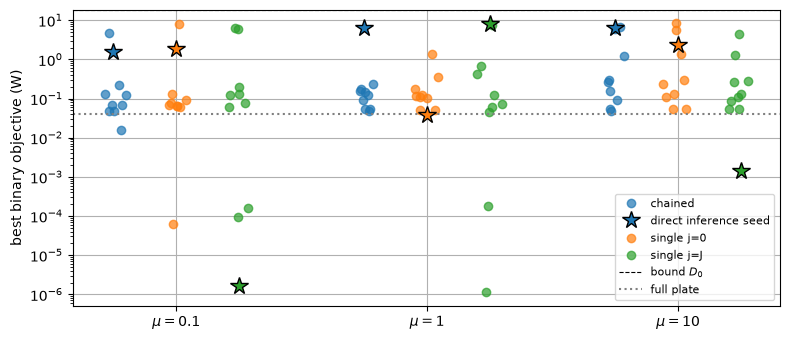

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
labels = ['chained', 'single j=0', 'single j=J']
for k, label in enumerate(labels):
    for i, mu_tot in enumerate([0.1, 1.0, 10.0]):
        B = np.maximum([o[1] for o in fitRes[(label, mu_tot)]], 1e-7)
        xs = np.full(len(B), 4*i + k) + 0.1*rng.standard_normal(len(B))
        ax.semilogy(xs[1:], B[1:], 'o', color=f"C{k}", alpha=0.7, label=label if i == 0 else None)
        # starts[0]: separable current fit of x_0 (direct inference seed)
        ax.semilogy(4*i + k, B[0], '*', color=f"C{k}", mec='k', ms=13, zorder=3,
                    label='direct inference seed' if i == 0 and k == 0 else None)
ax.axhline(gQCQP.current_dual, c='k', ls='--', lw=0.8, label='bound $D_0$')
ax.axhline(Pfull, c='gray', ls=':', label='full plate')
ax.set_xticks([1, 5, 9]); ax.set_xticklabels([r'$\mu = 0.1$', r'$\mu = 1$', r'$\mu = 10$'])
ax.set_ylabel('best binary objective (W)'); ax.legend(fontsize=8); ax.grid(True)
plt.tight_layout(); plt.show()

## Findings

Values vary by about $10^{-3}$ in $d$ between runs (GCD and the dual re-solve contain randomness); the trends below are stable.

1. **The GCD current lies inside the ellipsoid**, $d_0 \approx -(4.2 \ldots 4.9)\cdot 10^{-3}$ over four runs, and violates the reactive power by $c_\mathrm{im}/r^2 \approx 6\cdot 10^2$.
   Re-solving the unperturbed dual from the GCD multipliers already moves $d_0$ by about $2\cdot10^{-4}$: the near-kernel component is not reproducible.
2. **Targeting the original ellipsoid works**: $|d|$ drops below $3\cdot 10^{-4}$ within 2 steps (below the GCD accuracy $10^{-3}$). It then either decreases
   geometrically, by a factor of about 4 per step, to $3\cdot 10^{-8}$ after 8 steps, or stalls at $10^{-5}$ to $10^{-4}$ (run shown: $\sim 10^{-5}$ from step 3).
   The source perturbation saturates at $e_j \approx (3.1 \ldots 3.5)\cdot 10^{-3}$ and the dual value rises by $0.5\,\%$ (perturbed problems, not a bound for $V$). Every full step ($\eta = 1$) passes the linearity test;
   the first-order prediction is accurate to $10^{-5}$ relative.
3. **Strong duality of the perturbed problem is not reached**: the distance from its own ellipsoid stays at $d(V_j) \approx -(3.6 \ldots 4.8)\cdot 10^{-3}$.
   Targeting the own ellipsoid chases it: the source drifts linearly ($e_j$ grows by $(2.3 \ldots 2.6)\cdot10^{-3}$ per step), the dual value grows by $0.35$-$0.4\,\%$ per step,
   and the current passes through and beyond the original ellipsoid. The relative offset $\approx -4\cdot10^{-3}$ is a property of the re-solved dual
   (singular Lagrangian, smallest eigenvalue $\sim 10^{-14}$, unchanged by scraping), not of the source.
4. **The reactive residual is untouched** ($c_\mathrm{im}/r^2 \approx 6\cdot 10^2$ throughout): the step projects onto the real-power ellipsoid only.
5. **Chaining does not remove the near-kernel**: the smallest eigenvalue of $A_\mu$ is only about one order above that of a single $\hat A_j$
   (about $10^{-11}$ vs $10^{-12}$), so the near-kernels of the scraped Lagrangians largely coincide, and the chained center differs from $x_0$ by $20$-$95\,\%$ (run dependent) and lies at $d \approx -(5 \ldots 8)\cdot 10^{-4}$.
6. **The chained density fit brings no systematic gain.** Over 10 starts and $\mu \in \{0.1, 1, 10\}$, the median best binary structure is $0.06$-$0.3\,$W
   ($0.3$-$2\,\%$ of $D_0 = 17.5\,$W) for the chained and the single Lagrangians alike, and the maxima ($4.5$-$8.4\,$W, up to $48\,\%$ of $D_0$) are reached
   from individual starts in all three cases, the largest by the single unperturbed Lagrangian ($j = 0$, $\mu = 0.1$). The fit is dominated by its
   nonconvexity in $\rho$, and since $A_\mu$ is as singular as a single $\hat A_j$, chaining does not change the target. The finite-difference check of the
   adjoint gradient agrees to $1\,\%$, the limit set by cancellation in $f \sim 10^3$.

Scraping thus places the current on the physical real-power ellipsoid at the cost of a $0.3$-$0.35\,\%$ source change, but it does not regularize the dual and does not improve the inference:
the reactive constraint and the near-kernel need a separate treatment, e.g. projecting onto both global constraints or the kernel GCD stage.